# Navojoa climate — Time-series exploration
Modernized companion to the original Climatologia_Navojoa_Series_Tiempo notebook.
This version uses a daily calendar index: rolling windows refer to calendar days, unlike row-count windows in the original. Missing periods remain missing and may affect rolling averages.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns
root = Path.cwd()
if not (root / 'ClimatologiaNavojoa.txt').exists(): root = root.parent
sys.path.insert(0, str(root / 'scripts'))
from climate_processing import load_daily, monthly_climatology, annual_summary
df = load_daily()
df.head()


,date,precip_mm,tmax_c,tmin_c,year,month
0,1931-01-01,0.0,28.0,8.0,1931,1
1,1931-01-02,0.0,29.0,7.0,1931,1
2,1931-01-03,0.0,29.0,9.0,1931,1
3,1931-01-04,0.0,29.0,6.0,1931,1
4,1931-01-05,0.0,26.0,5.0,1931,1


Missing calendar days: 9536


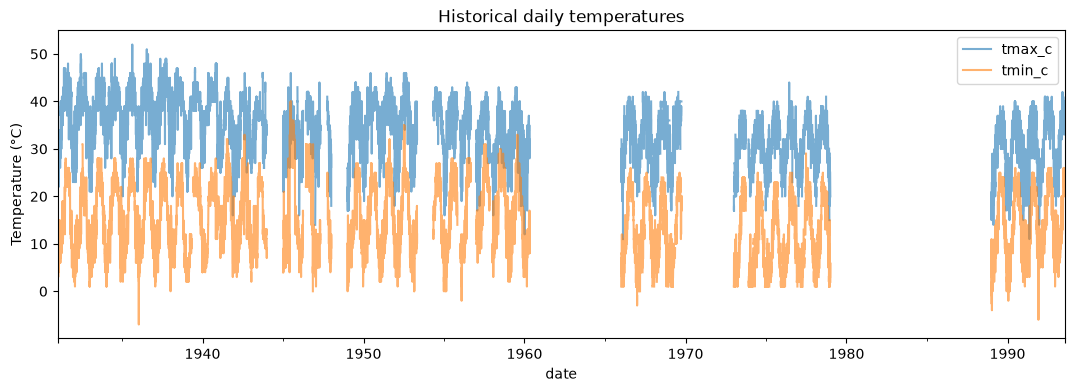

In [2]:
daily=df.set_index('date')[['precip_mm','tmax_c','tmin_c']].asfreq('D')
print('Missing calendar days:',daily.tmax_c.isna().sum())
daily[['tmax_c','tmin_c']].plot(figsize=(13,4),alpha=.6,title='Historical daily temperatures')
plt.ylabel('Temperature (°C)')
plt.show()


## 2. Calendar-day moving averages

A moving average smooths short-term fluctuations to reveal longer-lasting variation. The **7-day** window shows short-term patterns, **30-day** shows approximately monthly variation, and **365-day** captures variation across seasons. These are centered calendar-day windows. Missing observations are not filled in; a window needs sufficient coverage to produce an estimate.

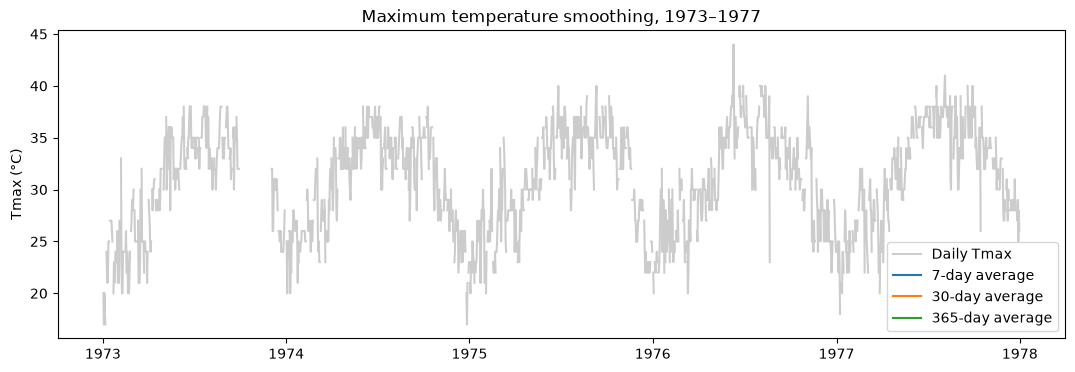

In [3]:
series=daily.loc['1973':'1977','tmax_c']
fig,ax=plt.subplots(figsize=(13,4))
ax.plot(series,color='gray',alpha=.4,label='Daily Tmax')
for days in (7,30,365):
    ax.plot(series.rolling(f'{days}D',center=True,min_periods=days).mean(),label=f'{days}-day average')
ax.set(ylabel='Tmax (°C)',title='Maximum temperature smoothing, 1973–1977')
ax.legend()
plt.show()


## 3. Data coverage and annual summaries

Before comparing annual rainfall totals, inspect how many daily precipitation records were available each year. An incomplete year's *observed* total may be much lower simply because days were missing.

In [4]:
annual=annual_summary(df)
display(annual.head(10))
print('Precipitation observations by year:')
display(annual[['year','precipitation_observations']].tail(10))


,year,observed_precip_total_mm,precipitation_observations,mean_tmax_c,mean_tmin_c
0,1931,446.0,365,37.334247,15.350685
1,1932,181.0,366,36.581169,11.711039
2,1933,139.0,350,37.588571,14.911429
3,1934,321.0,365,38.767123,15.879452
4,1935,469.0,365,37.509589,15.673973
5,1936,396.0,366,38.707650,15.907104
6,1937,239.6,361,39.476454,15.216066
7,1938,136.0,357,38.644258,14.764706
8,1939,170.0,323,37.606811,15.547988
9,1940,861.2,366,38.758242,16.049180


Precipitation observations by year:


,year,precipitation_observations
33,1974,305
34,1975,306
35,1976,308
36,1977,307
37,1978,310
38,1989,332
39,1990,365
40,1991,365
41,1992,366
42,1993,212


## 4. What these plots can and cannot tell us

Time-series visualization and moving averages help describe short- and medium-term changes in recorded temperatures. They do not, by themselves, establish a statistically significant warming trend or support climate-change attribution.